In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kritikseth/fruit-and-vegetable-image-recognition")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fruit-and-vegetable-image-recognition' dataset.
Path to dataset files: /kaggle/input/fruit-and-vegetable-image-recognition


In [3]:
import os

In [4]:
os.listdir(path)

['validation', 'test', 'train']

In [5]:
train_path=os.path.join(path,'train')
test_path=os.path.join(path,'test')
val_path=os.path.join(path,'validation')

In [6]:
print("train_path")
print("test_path")
print("val_path")

train_path
test_path
val_path


In [7]:
os.listdir(train_path)
print()
os.listdir(test_path)
print()
os.listdir(val_path)

['capsicum',
 'sweetcorn',
 'orange',
 'tomato',
 'turnip',
 'ginger',
 'raddish',
 'pomegranate',
 'pineapple',
 'jalepeno',
 'apple',
 'carrot',
 'lettuce',
 'bell pepper',
 'eggplant',
 'beetroot',
 'kiwi',
 'pear',
 'cabbage',
 'cauliflower',
 'paprika',
 'lemon',
 'sweetpotato',
 'grapes',
 'cucumber',
 'corn',
 'banana',
 'garlic',
 'chilli pepper',
 'watermelon',
 'mango',
 'peas',
 'onion',
 'potato',
 'spinach',
 'soy beans']

In [8]:
print(train_path)
print(test_path)
print(val_path)

/kaggle/input/fruit-and-vegetable-image-recognition/train
/kaggle/input/fruit-and-vegetable-image-recognition/test
/kaggle/input/fruit-and-vegetable-image-recognition/validation


In [9]:
pear_image=os.path.join(train_path,"pear")  #we can write there banana or other class
pear_image

'/kaggle/input/fruit-and-vegetable-image-recognition/train/pear'

In [10]:
pear_image,os.listdir(pear_image)[6]

('/kaggle/input/fruit-and-vegetable-image-recognition/train/pear',
 'Image_4.jpg')

In [11]:
pear_path_image=os.path.join(pear_image,os.listdir(pear_image)[6])

In [12]:
from PIL import Image

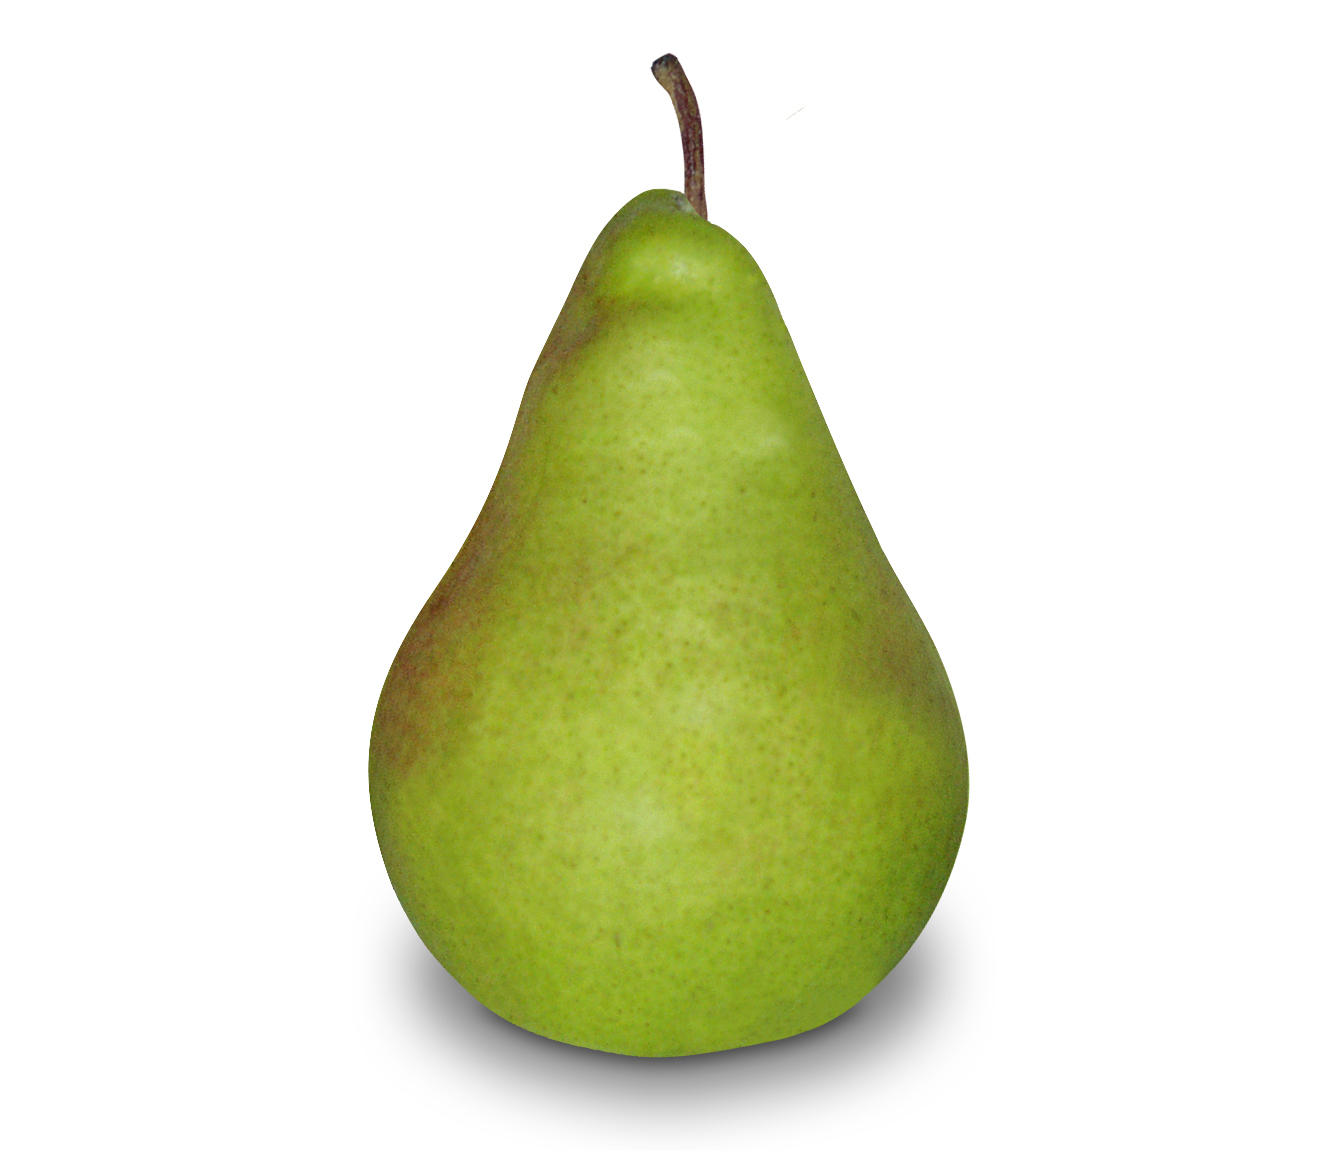

In [13]:
Image.open(pear_path_image)

In [14]:
import cv2
import matplotlib.pyplot as plt

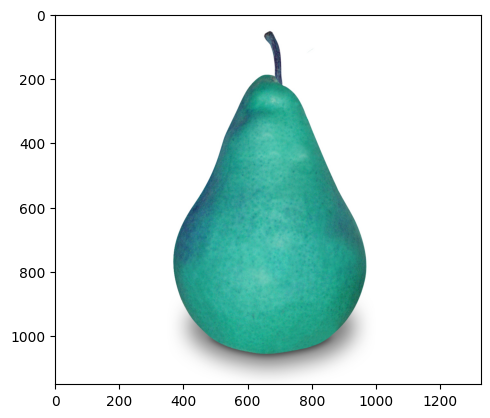

In [15]:
img=cv2.imread(pear_path_image)
plt.imshow(img)

In [16]:
from tensorflow import keras
from keras import layers

In [17]:
train_data= keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(180,180),
    batch_size=32,
    shuffle=True
    )

Found 3115 files belonging to 36 classes.


In [18]:
test_data=keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(180,180),
    batch_size=32,
    shuffle=False
    )

Found 359 files belonging to 36 classes.


In [19]:
valid_data=keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(180,180),
    batch_size=32,
    shuffle=False
    )

Found 351 files belonging to 36 classes.


In [20]:
len(train_data.class_names)

36

In [21]:
model=keras.Sequential(
    [
        layers.Rescaling(1./255),
        layers.Conv2D(32,3,activation="relu",padding="same"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64,3,activation="relu",padding="same"),
        layers.MaxPooling2D(2),
        layers.Conv2D(128,3,activation="relu",padding="same"),
        layers.MaxPooling2D(2),
        layers.Conv2D(256,3,activation="relu",padding="same"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128,activation="relu"),
        layers.Dense(len(train_data.class_names),activation="softmax")
    ]
)

In [22]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [23]:
from IPython.core import history
history=model.fit(train_data,validation_data=valid_data,epochs=20)

Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 747ms/step - accuracy: 0.0478 - loss: 3.4529 - val_accuracy: 0.0712 - val_loss: 3.0887
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 58s 596ms/step - accuracy: 0.1217 - loss: 3.0087 - val_accuracy: 0.2222 - val_loss: 2.5498
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 85s 631ms/step - accuracy: 0.2456 - loss: 2.5306 - val_accuracy: 0.3675 - val_loss: 1.9439
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 72s 738ms/step - accuracy: 0.3403 - loss: 2.1948 - val_accuracy: 0.5641 - val_loss: 1.5095
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 70s 716ms/step - accuracy: 0.4019 - loss: 1.9750 - val_accuracy: 0.6296 - val_loss: 1.2679
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 84s 859ms/step - accuracy: 0.4909 - loss: 1.6631 - val_accuracy: 0.6781 - val_loss: 1.1079
Epoch 7/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 80s 817ms/step - accuracy: 0.5634 - loss: 1.4084 - val_accuracy: 0.7920 - val_loss: 0.8072
Epoch 8/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 75s 765ms/step - accuracy: 0.6600 - loss: 1.0994 - val_accu

In [24]:
model.save("fruit_vegetable.keras")

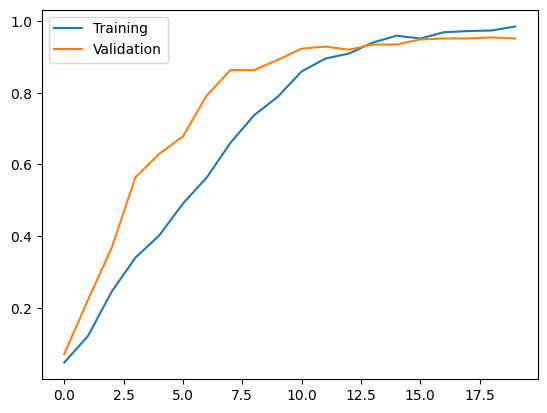

In [25]:
plt.plot(history.history["accuracy"],label="Training")
plt.plot(history.history["val_accuracy"],label="Validation")
plt.legend()
plt.show()

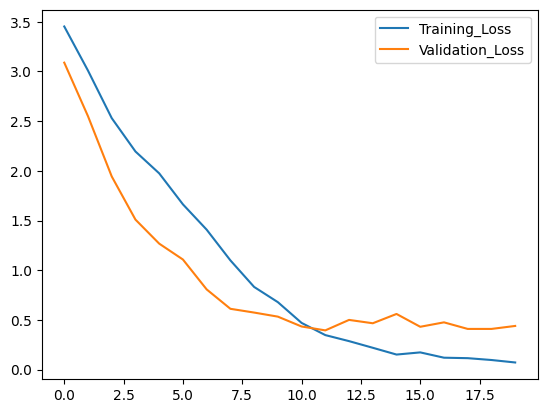

In [26]:
plt.plot(history.history["loss"],label="Training_Loss")
plt.plot(history.history["val_loss"],label="Validation_Loss")
plt.legend()
plt.show()

In [27]:
import tensorflow as tf
from tensorflow.keras.utils import load_img,img_to_array

In [30]:
import numpy as np
banana_path=os.path.join(test_path,"banana")
img_path=os.path.join(banana_path,os.listdir(banana_path)[0])
img=load_img(img_path,target_size=(180,180))
img= img_to_array(img)
img=np.expand_dims(img,axis=0)
pred=model.predict(img)
score=tf.nn.softmax(pred)
prediction=train_data.class_names[np.argmax(score)]
#print(prediction)

confidence=np.max(score)
print(f"Predicted class: {prediction}")
print(f"Confidence Score: {confidence}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
Predicted class: banana
Confidence Score: 0.07165214419364929


In [31]:
import gradio as gr
def pred_image(img):
  img=load_img(img,target_size=(180,180))
  img=img_to_array(img)
  img=np.expand_dims(img,axis=0)
  pred=model.predict(img)
  score=tf.nn.softmax(pred)
  prediction=train_data.class_names[np.argmax(score)]
  confidence=np.max(score)
  return prediction
  return confidence

In [32]:
app = gr.Interface(fn=pred_image,inputs=gr.Image(type="filepath"),outputs="text")

In [33]:
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8fc58b38214b9c85b6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
